In [ ]:
# 1.Loading the Taxis Dataset

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Display plots inside the notebook
%matplotlib inline

# Set a consistent style for charts
sns.set_theme(style="whitegrid")


In [24]:
df = sns.load_dataset("taxis")
# Display the first five rows
df.head()


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [26]:
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Summary statistics
df.describe()

Dataset shape: (6433, 14)
<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), flo

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6433,6433,6433.000000,6433.000000,6433.000000,6433.00000,6433.000000,6433.000000
mean,2019-03-16 08:31:28.514223,2019-03-16 08:45:49.491216,1.539251,3.024617,13.091073,1.97922,0.325273,18.517794
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.00000,0.000000,1.300000
25%,2019-03-08 15:50:34,2019-03-08 16:12:51,1.000000,0.980000,6.500000,0.00000,0.000000,10.800000
50%,2019-03-15 21:46:58,2019-03-15 22:06:44,1.000000,1.640000,9.500000,1.70000,0.000000,14.160000
75%,2019-03-23 17:41:38,2019-03-23 17:51:56,2.000000,3.210000,15.000000,2.80000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,33.20000,24.020000,174.820000
std,NaN,NaN,1.203768,3.827867,11.551804,2.44856,1.415267,13.815570


In [ ]:
# 2. Handling Missing Values

In [27]:
# Count missing values in every column
print(df.isnull().sum())

# Show only columns that contain missing values
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# Calculate missing-value percentages
missing_percentage = (df.isnull().mean() * 100).round(2)
print(missing_percentage[missing_percentage > 0])

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64
payment            0.68
pickup_zone        0.40
dropoff_zone       0.70
pickup_borough     0.40
dropoff_borough    0.70
dtype: float64


In [8]:
# Work on a copy of the original dataset
df_clean = df.copy()

# Convert pickup and dropoff to datetime
df_clean["pickup"] = pd.to_datetime(
    df_clean["pickup"], errors="coerce"
)
df_clean["dropoff"] = pd.to_datetime(
    df_clean["dropoff"], errors="coerce"
)

# Remove rows missing critical values
df_clean = df_clean.dropna(subset=["pickup", "fare"])

# Fill missing numerical values with the median
numerical_columns = [
    "passengers", "distance", "fare",
    "tip", "tolls", "total"
]

for col in numerical_columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing categorical values with the mode
categorical_columns = [
    "payment", "pickup_zone", "pickup_borough",
    "dropoff_zone", "dropoff_borough"
]

for col in categorical_columns:
    if df_clean[col].isnull().any():
        if not df_clean[col].mode().empty:
            df_clean[col] = df_clean[col].fillna(
                df_clean[col].mode()[0]
            )

# Check missing values after cleaning
print(df_clean.isnull().sum())
print("Cleaned dataset shape:", df_clean.shape)


pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64
Cleaned dataset shape: (6433, 14)


In [ ]:
#3. Create the five Matplotlib/Pandas visualizations

In [ ]:
# Line Chart-Fare over time

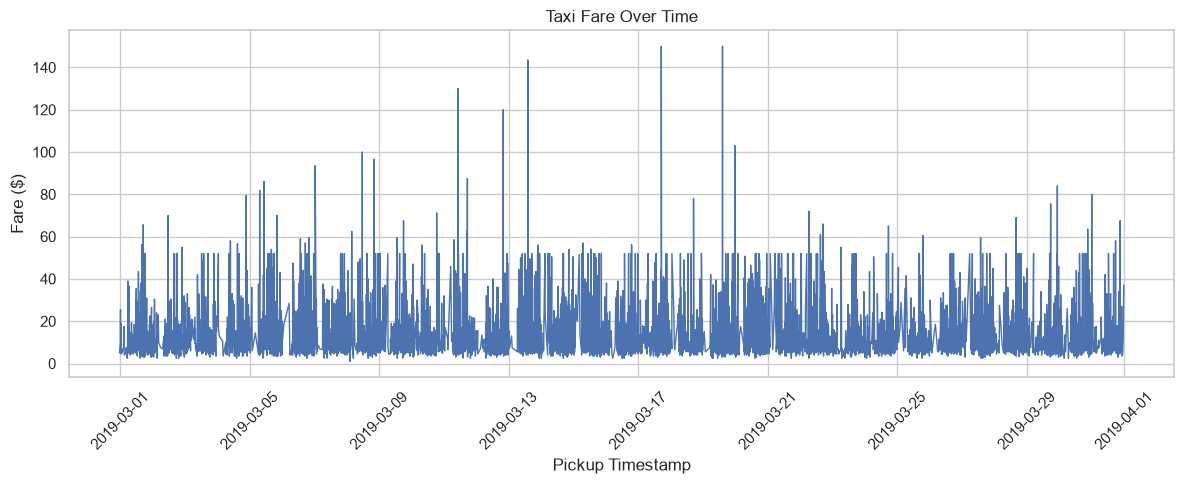

In [22]:
# Sort records by pickup timestamp
line_data = df_clean.sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(
    line_data["pickup"],
    line_data["fare"],
    linewidth=1
)

plt.title("Taxi Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Bar Chart-Total fare by pickup borough

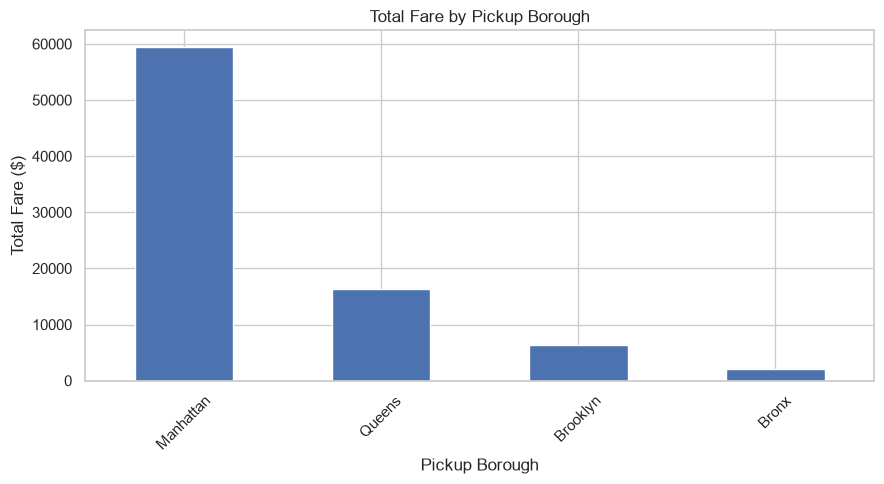

In [10]:
borough_fare = df_clean.groupby(
    "pickup_borough"
)["fare"].sum().sort_values(ascending=False)

borough_fare.plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Fare by Pickup Borough"
)

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Pie Chart-Trips by payment method

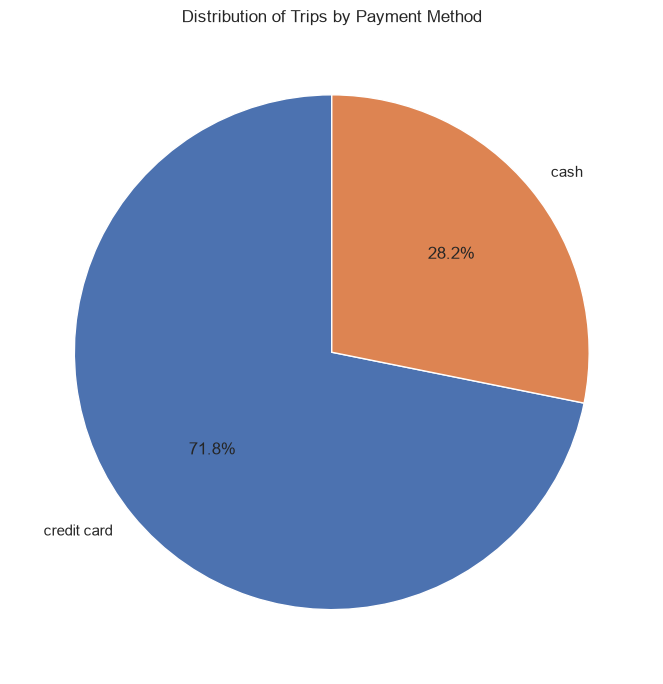

In [20]:
payment_counts = df_clean["payment"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.tight_layout()
plt.show()

In [ ]:
# Histogram-Distribution of trip distance

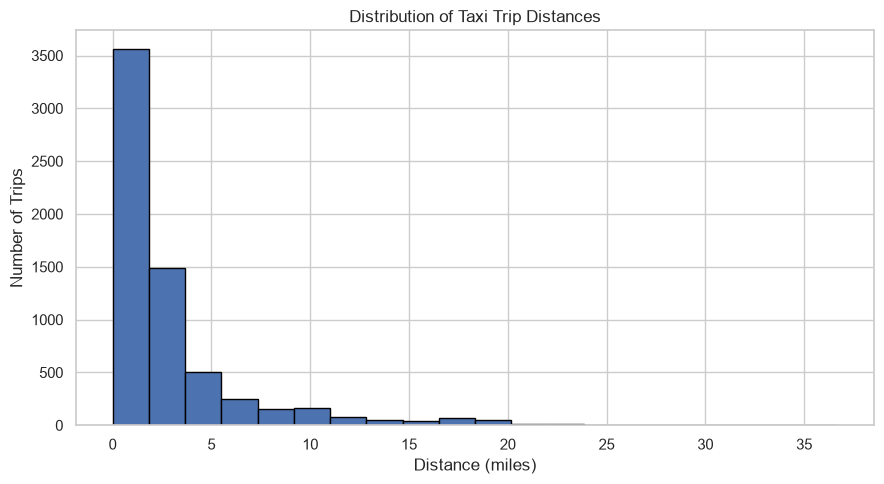

In [12]:
plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["distance"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

In [ ]:
# Box Plot:Tip amounts by pickup borough

<Figure size 1000x500 with 0 Axes>

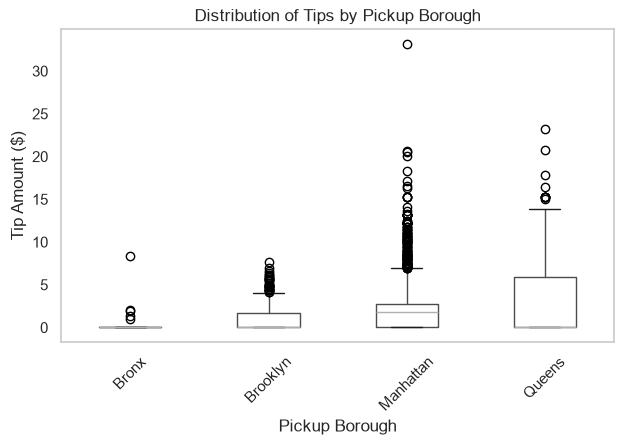

In [29]:
plt.figure(figsize=(10, 5))

df_clean.boxplot(
    column="tip",
    by="pickup_borough",
    grid=False
)

plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
 #Count plot: Number of trips by pickup borough

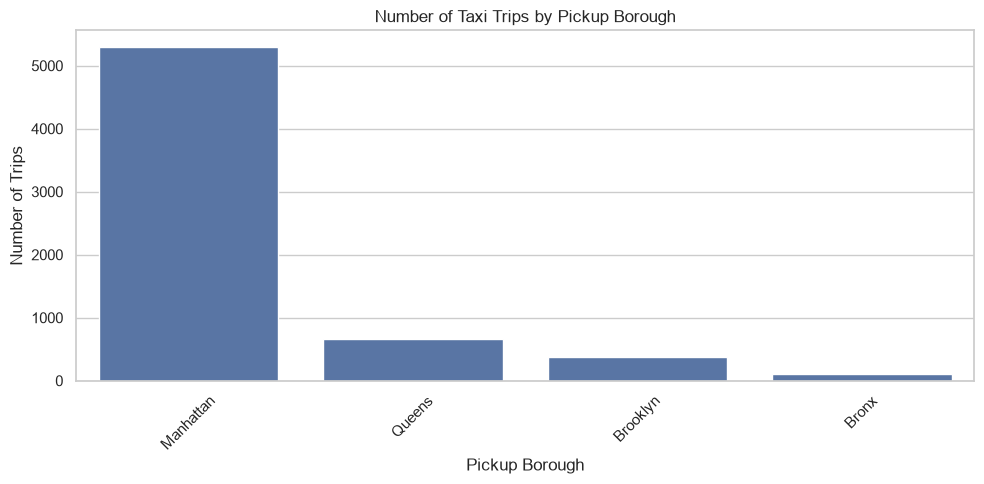

In [14]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="pickup_borough",
    order=df_clean["pickup_borough"].value_counts().index
)

plt.title("Number of Taxi Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
Scatter plot: Distance versus fare

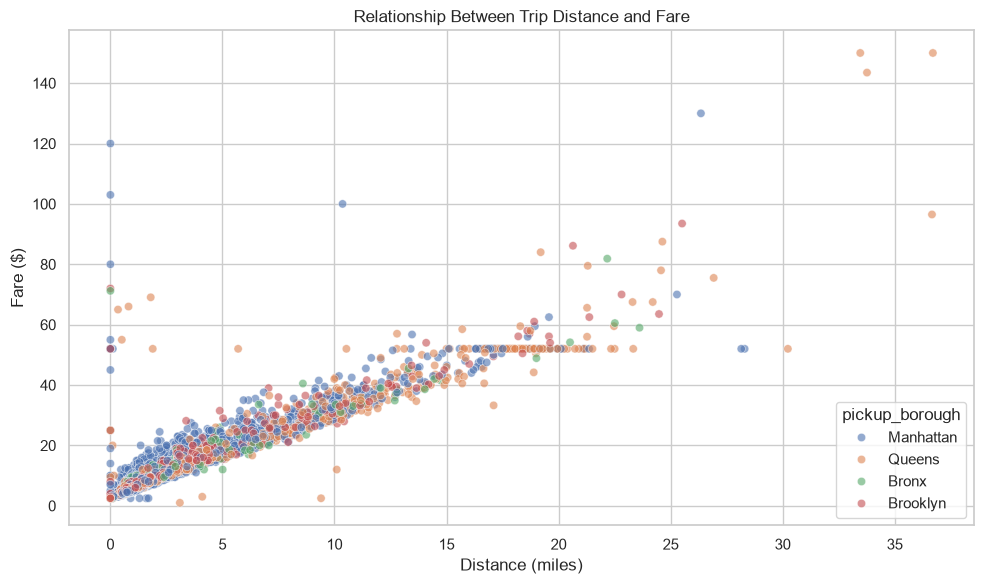

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.6
)

plt.title("Relationship Between Trip Distance and Fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()

In [ ]:
#Heatmap: Correlation between numerical variables

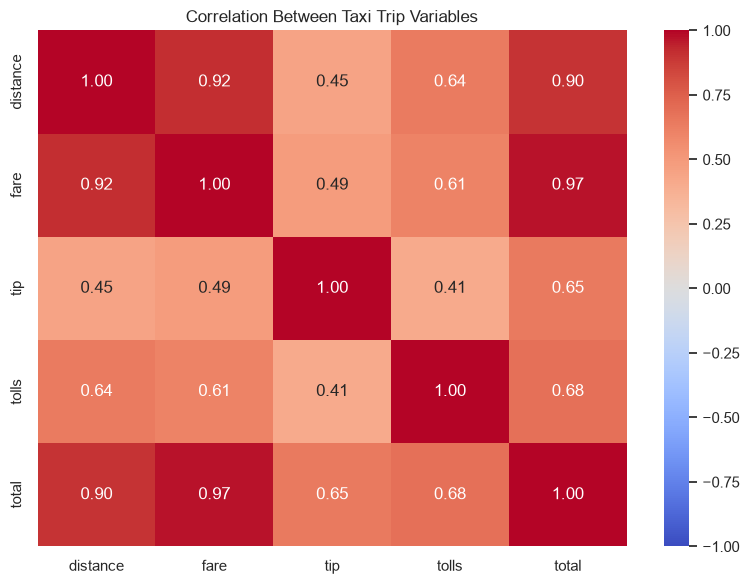

In [16]:
numeric_columns = [
    "distance", "fare", "tip", "tolls", "total"
]

correlation_matrix = df_clean[
    numeric_columns
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Taxi Trip Variables")
plt.tight_layout()
plt.show()

In [ ]:
# Pair plot: Pairwise relationships

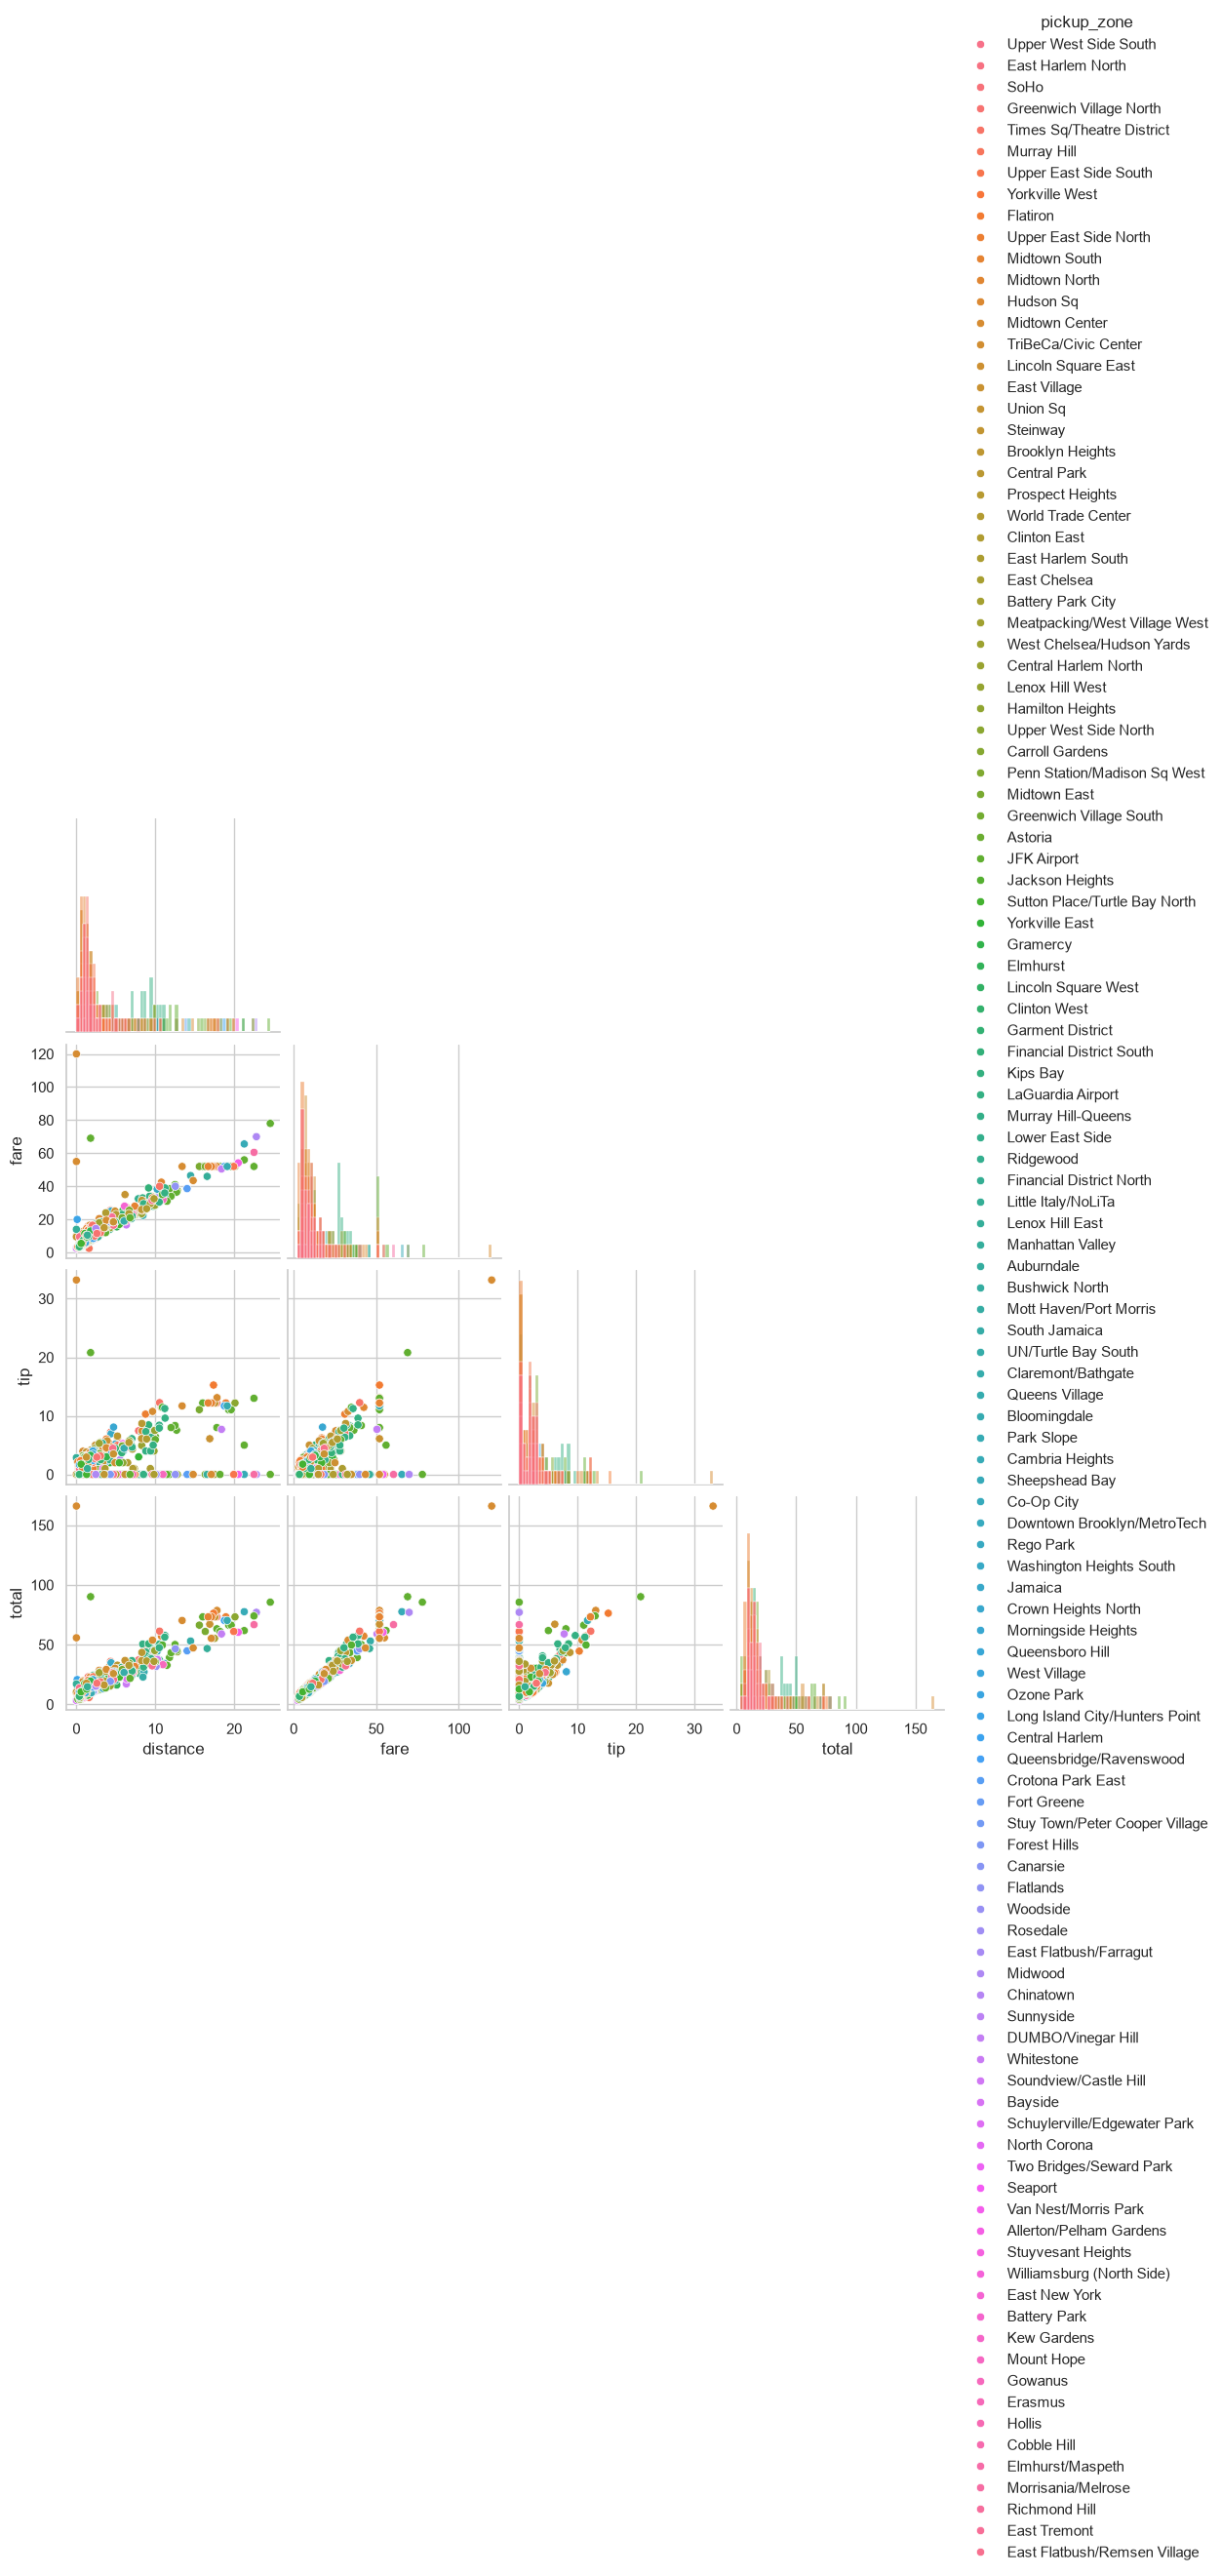

In [17]:
pair_columns = [
    "distance", "fare", "tip", "total", "pickup_zone"
]

# Use a sample to make the pair plot easier to render
pair_data = df_clean[pair_columns].dropna()

if len(pair_data) > 1000:
    pair_data = pair_data.sample(
        n=1000,
        random_state=42
    )

sns.pairplot(
    data=pair_data,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist",
    corner=True
)

plt.show()


In [ ]:
#Violin plot: Fare by payment method

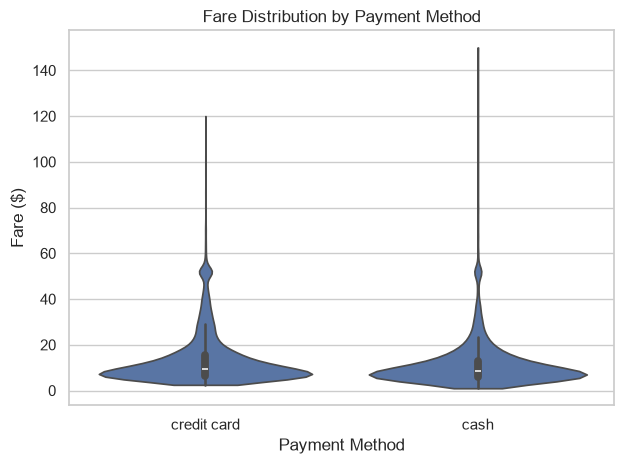

In [28]:
sns.violinplot(
    data=df_clean,
    x="payment",
    y="fare",
    cut=0
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare ($)")
plt.tight_layout()
plt.show()